In [1]:
import cv2
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from preprocessing import crop_frame
import ruptures as rpt


In [2]:
# !pip install ruptures

In [6]:
# def check_excluded_pixels(frame, min_brightness=10, corner=60, show=True):
#     """
#     Check which pixels mean_normalized_red() throws away on a (cropped) BGR frame.
#     Prints: % of pixels excluded, and r+g+b stats inside the four corner blocks
#     (corner x corner px at each frame corner, which should lie in the black triangles).
#     If the corner max/p99 is >= min_brightness, those corner pixels are NOT being excluded.
#     """
#     f = frame.astype(np.float32)
#     total = f[:, :, 0] + f[:, :, 1] + f[:, :, 2]
#     excluded = total < min_brightness
#     h, w = total.shape

#     print(f"excluded: {excluded.mean()*100:.2f}% of pixels (threshold r+g+b < {min_brightness})")

#     corners = {
#         "top-left": total[:corner, :corner], "top-right": total[:corner, -corner:],
#         "bottom-left": total[-corner:, :corner], "bottom-right": total[-corner:, -corner:],
#     }
#     for name, blk in corners.items():
#         print(f"  {name:<12} r+g+b: max={blk.max():5.1f}  p99={np.percentile(blk,99):5.1f}  "
#               f"excluded={(blk < min_brightness).mean()*100:5.1f}%")

#     # excluded pixels that are NOT in the corner blocks (e.g. dark lumen)
#     corner_mask = np.zeros_like(excluded)
#     corner_mask[:corner, :corner] = corner_mask[:corner, -corner:] = True
#     corner_mask[-corner:, :corner] = corner_mask[-corner:, -corner:] = True
#     print(f"excluded outside corner blocks: {(excluded & ~corner_mask).mean()*100:.2f}% of pixels")

#     if show:
#         import matplotlib.pyplot as plt
#         fig, ax = plt.subplots(1, 2, figsize=(12, 5))
#         ax[0].imshow(frame[:, :, ::-1]); ax[0].set_title("cropped frame"); ax[0].axis("off")
#         ax[1].imshow(excluded, cmap="gray"); ax[1].set_title("white = excluded by min_brightness"); ax[1].axis("off")
#         plt.tight_layout(); plt.show()
#     return excluded

excluded: 0.00% of pixels (threshold r+g+b < 10)
  top-left     r+g+b: max= 48.0  p99= 46.0  excluded=  0.0%
  top-right    r+g+b: max= 48.0  p99= 48.0  excluded=  0.0%
  bottom-left  r+g+b: max= 48.0  p99= 48.0  excluded=  0.0%
  bottom-right r+g+b: max= 48.0  p99= 46.0  excluded=  0.0%
excluded outside corner blocks: 0.00% of pixels


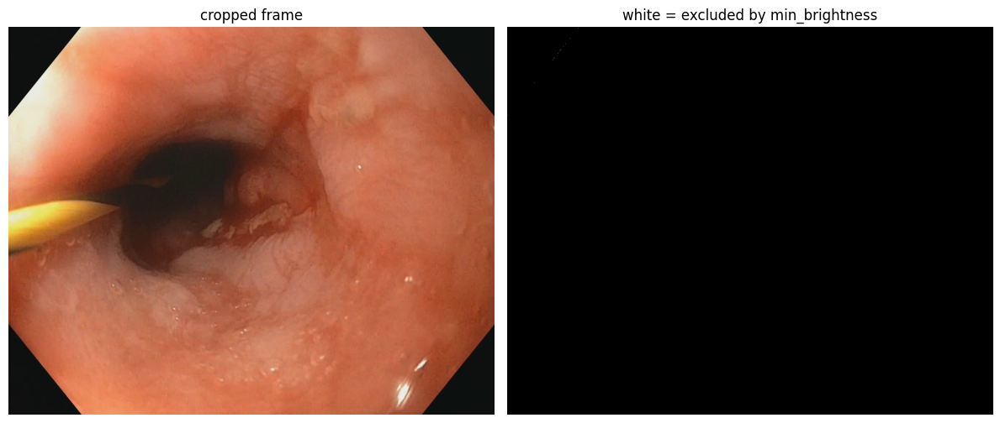

In [7]:
# frame_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\sample_frames\frame_0259.png"

# frame = cv2.imread(frame_path)          # BGR, same as the video frames
# if frame is None:
#     raise FileNotFoundError(f"Could not read image: {frame_path}")

# cropped = crop_frame(frame)             # raises ValueError if the width isn't 1920
# excluded = check_excluded_pixels(cropped)

In [5]:
def mean_normalized_red(frame, min_brightness=10, epsilon=1e-6):
    """
    Compute mean-normalized-red for a frame: the average, per pixel, of how
    red-dominant that pixel's color is -- r / (r+g+b), scaled to 0-255.
    Independent of raw brightness, unlike a simple mean-red check.

    Pixels whose total brightness (r+g+b) is below `min_brightness` are
    excluded before averaging -- near-black pixels (e.g. the fixed corner
    triangles left over after crop_frame()) where r/(r+g+b) isn't a
    meaningful color signal.

    Expects a BGR frame (OpenCV's default). Returns a float in [0, 255].
    """
    frame = frame.astype(np.float32)
    b = frame[:, :, 0]
    g = frame[:, :, 1]
    r = frame[:, :, 2]

    total = r + g + b
    valid = total >= min_brightness

    if not np.any(valid):
        return 0.0

    ratio = np.zeros_like(total)
    ratio[valid] = r[valid] / (total[valid] + epsilon)

    pixel_score = 255.0 * ratio
    return float(pixel_score[valid].mean())

In [9]:
def summarize(values):
    values = np.asarray(values)
    plain_median = float(np.median(values))

    above_100 = values[values >= 100]
    p90 = np.percentile(above_100, 90)
    trimmed = above_100[above_100 <= p90]
    trimmed_median = float(np.median(trimmed))

    return {
        "n_frames": len(values),
        "n_after_floor": len(above_100),
        "n_after_trim": len(trimmed),
        "median": plain_median,
        "trimmed_median": trimmed_median,
    }

video_folder = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos"
video_extensions = ("*.mp4", "*.avi", "*.mov", "*.mkv")

video_paths = []
for ext in video_extensions:
    video_paths.extend(glob.glob(os.path.join(video_folder, "**", ext), recursive=True))

results = []

for video_path in video_paths:
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Could not open {video_path} -- skipping")
        continue

    scores = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
            
        try:
            cropped = crop_frame(frame)
        except ValueError:
            continue
        scores.append(mean_normalized_red(cropped))
    cap.release()

    if not scores:
        print(f"No frames read for {video_path} -- skipping")
        continue

    values = np.array(scores)

    results.append({"video": os.path.basename(video_path), **summarize(values)})

print(f"{'video':<30} {'n':>5} {'n_after_trim':>8} {'median':>14} {'trimmed_median':>14}")
for r in results:
    print(f"{r['video']:<30} {r['n_frames']:>5} {r['n_after_trim']:>8.1f} {r['median']:>14.1f} {r['trimmed_median']:>14.1f}")

# ---------- CONFIG ----------
video_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O983C19_12-06-25_101337.mp4"

video                              n n_after_trim         median trimmed_median
O983C19_12-06-25_101337.mp4      754    678.0          151.3          146.8
O983C20_12-06-25_101352.mp4      390    351.0          136.3          135.9
O99242D_11-07-25_093158.mp4     1197   1077.0          120.6          120.2
O9C3E27_24-10-25_090146.mp4      239    215.0          132.5          132.4
O9E3CEC_07-01-26_092102.mp4     1716    981.0          122.9          128.5
OA08324_23-03-26_102243.mp4      754    586.0          125.6          126.3
OA2459C_05-05-26_102237.mp4     1091    982.0          129.9          128.8
OA245A0_05-05-26_102303.mp4     1295    778.0          121.0          123.3


In [10]:
def compute_mnr_series(video_path):
    """Apply crop_frame + mean_normalized_red to every frame of a video.
    Returns a numpy array of values (one per frame, NaN where a frame failed)."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("  Could not open — skipping")
        return None

    values = []
    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        try:
            cropped = crop_frame(frame)
            values.append(mean_normalized_red(cropped))
        except ValueError as e:
            print(f"  frame {idx}: crop failed ({e}) — skipping")
            values.append(np.nan)
        idx += 1
        
    cap.release()
    print(f"frames analyzed: {len(values)}  |  min={np.nanmin(values):.1f}  max={np.nanmax(values):.1f}  mean={np.nanmean(values):.1f}")
    
    return np.array(values)


In [48]:
values = compute_mnr_series(video_path)

frames analyzed: 1091  |  min=120.0  max=172.2  mean=130.9


frames analyzed: 1295  |  min=63.8  max=156.9  mean=110.2    ---- OA245A0_05-05-26_102303.mp4

frames analyzed: 239  |  min=129.0  max=141.5  mean=133.2 ---- O9C3E27_24-10-25_090146.mp4

frames analyzed: 1197  |  min=112.0  max=159.3  mean=122.5 ----  O99242D_11-07-25_093158.mp4

frames analyzed: 754  |  min=67.7  max=146.7  mean=121.3  ---- OA08324_23-03-26_102243.mp4

frames analyzed: 754  |  min=124.3  max=188.1  mean=156.1 ---- O983C19_12-06-25_101337.mp4


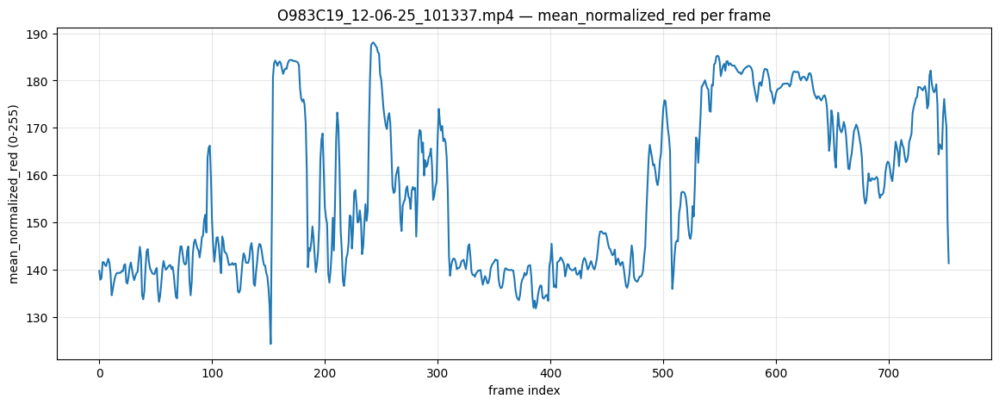

In [12]:
# ---------- PLOT ----------

def plot_mean_normalized_red(video_path, values):
    plt.figure(figsize=(14, 5))
    plt.plot(values)
    plt.title(f"{video_path.split(chr(92))[-1]} — mean_normalized_red per frame")
    plt.xlabel("frame index")
    plt.ylabel("mean_normalized_red (0-255)")
    plt.grid(alpha=0.3)
    plt.show()


plot_mean_normalized_red(video_path, values)

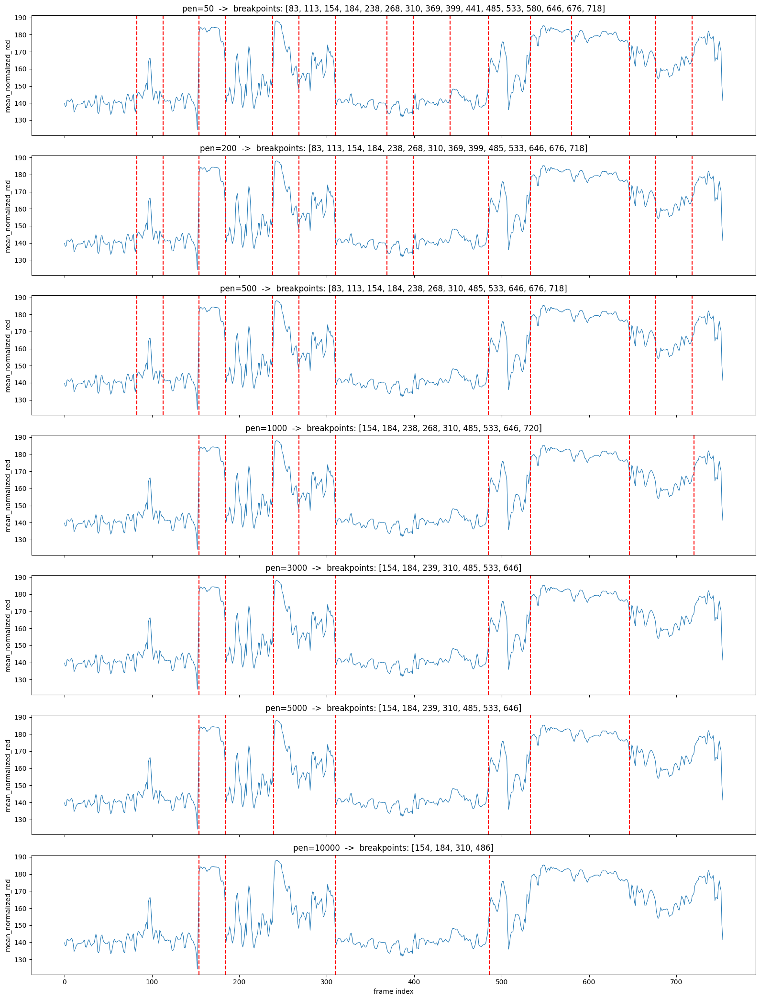

In [13]:
import ruptures as rpt

signal = np.array(values)

pens_to_try = [50, 200, 500, 1000, 3000, 5000, 10000]
breakpoints_by_pen = {}

fig, axes = plt.subplots(len(pens_to_try), 1, figsize=(16, 3*len(pens_to_try)), sharex=True)

for ax, pen in zip(axes, pens_to_try):
    algo = rpt.Pelt(model="l2", min_size=30, jump=1).fit(signal)
    bkps = algo.predict(pen=pen)          # last value is always len(signal), not a real breakpoint
    breakpoints_by_pen[pen] = bkps

    ax.plot(signal, linewidth=0.8)
    for bkp in bkps[:-1]:
        ax.axvline(x=bkp, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"pen={pen}  ->  breakpoints: {bkps[:-1]}")
    ax.set_ylabel("mean_normalized_red")

axes[-1].set_xlabel("frame index")
plt.tight_layout()
plt.show()

In [14]:
def shading_plot(values, all_segs, survivors):
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(values, linewidth=0.8, color="tab:blue")
    
    for s in all_segs:
        ax.axvline(x=s["start"], color="gray", linestyle=":", linewidth=0.8)
    
    for s in survivors:
        ax.axvspan(s["start"], s["end"], color="green", alpha=0.2)
    
    ax.set_title("Survivors shaded green (pen=500, range<=20)")
    ax.set_xlabel("frame index")
    ax.set_ylabel("mean_normalized_red")
    plt.tight_layout()
    plt.show()

In [15]:
def filter_by_stability(values, bkps, max_range=20, low_pct=10, high_pct=90):
    """
    Drop segments that are not genuinely flat (90-10 percentile range too wide).
    No length filter -- that's applied separately, later.
    """
    values = np.asarray(values)
    bkps = list(bkps)
    if bkps[-1] != len(values):
        bkps.append(len(values))
    starts = [0] + bkps[:-1]
    ends = bkps

    all_segments = []
    for start, end in zip(starts, ends):
        seg = values[start:end]
        p_low, p_high = np.percentile(seg, [low_pct, high_pct])
        all_segments.append({
            "start": start, "end": end, "length": end - start,
            "mean": float(seg.mean()),
            "range_90_10": float(p_high - p_low),
        })

    survivors = [s for s in all_segments if s["range_90_10"] <= max_range]
    return survivors, all_segments

All segments:
     0-83   len=83   mean= 139.6 range_90_10=  7.2
    83-113  len=30   mean= 147.9 range_90_10= 17.4
   113-154  len=41   mean= 140.6 range_90_10=  8.9
   154-184  len=30   mean= 181.8 range_90_10=  8.3
   184-238  len=54   mean= 149.8 range_90_10= 23.1
   238-268  len=30   mean= 172.2 range_90_10= 30.9
   268-310  len=42   mean= 161.0 range_90_10= 15.0
   310-485  len=175  mean= 140.0 range_90_10=  7.9
   485-533  len=48   mean= 158.1 range_90_10= 23.8
   533-646  len=113  mean= 180.1 range_90_10=  7.0
   646-676  len=30   mean= 168.0 range_90_10=  8.2
   676-718  len=42   mean= 160.7 range_90_10= 10.0
   718-754  len=36   mean= 173.1 range_90_10= 13.3

Survivors (range_90_10<=20):
     0-83   len=83   mean= 139.6 range_90_10=  7.2
   113-154  len=41   mean= 140.6 range_90_10=  8.9
   154-184  len=30   mean= 181.8 range_90_10=  8.3
   310-485  len=175  mean= 140.0 range_90_10=  7.9
   533-646  len=113  mean= 180.1 range_90_10=  7.0
   646-676  len=30   mean= 168.0 range

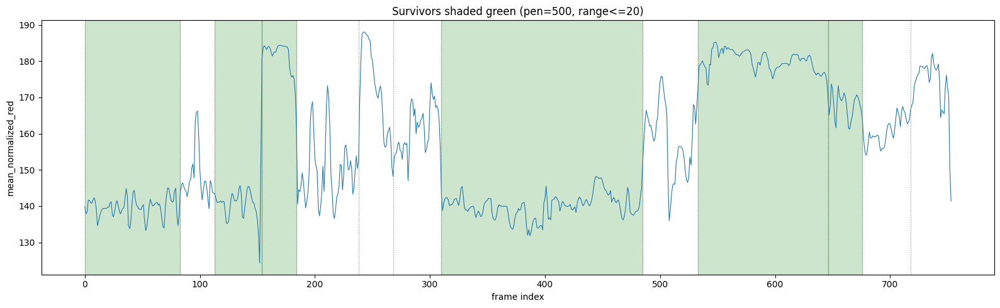

In [16]:
survivors, all_segs = filter_by_stability(values, breakpoints_by_pen[500], max_range=10)

print("All segments:")
for s in all_segs:
    print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range_90_10={s['range_90_10']:5.1f}")

print("\nSurvivors (range_90_10<=20):")
for s in survivors:
    print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range_90_10={s['range_90_10']:5.1f}")

shading_plot(values, all_segs, survivors)

In [306]:
# pooled = np.concatenate([values[s["start"]:s["end"]] for s in survivors])
# pooled_filtered = pooled[pooled <= 160]
# median = float(np.median(pooled_filtered))

# print("pooled frames:", len(pooled), " after removing >160:", len(pooled_filtered))
# print("median:", round(median, 1))

pooled frames: 472  after removing >160: 299
median: 140.2


In [303]:
# def filter_by_range(values, bkps, max_range=20):
#     """
#     Drop segments whose plain range (max-min) exceeds max_range.
#     No percentile trimming, no length filter -- just raw max-min.
#     """
#     values = np.asarray(values)
#     bkps = list(bkps)
#     if bkps[-1] != len(values):
#         bkps.append(len(values))
#     starts = [0] + bkps[:-1]
#     ends = bkps

#     all_segments = []
#     for start, end in zip(starts, ends):
#         seg = values[start:end]
#         all_segments.append({
#             "start": start, "end": end, "length": end - start,
#             "mean": float(seg.mean()),
#             "range": float(seg.max() - seg.min()),
#         })

#     survivors = [s for s in all_segments if s["range"] <= max_range]
#     return survivors, all_segments


# survivors, all_segs = filter_by_range(values, breakpoints_by_pen[500], max_range=20)

# print("All segments at pen=500:")
# for s in all_segs:
#     print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range={s['range']:5.1f}")

# print("\nSurvivors (range<=20):")
# for s in survivors:
#     print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range={s['range']:5.1f}")


# shading_plot(values, all_segs, survivors)

151.2943115234375

In [17]:
def filter_by_containing_baseline(values, survivors, low_pct=10, high_pct=90):
    """
    Baseline = median of pooled per-frame values from just the surviving (flat)
    segments -- not the whole noisy video. Then keep only segments whose OWN
    value range (10-90 percentile) actually contains that baseline. A segment
    that's flat but sitting entirely above/below baseline (e.g. a stable
    close-up/glare plateau) gets dropped -- no arbitrary distance cutoff needed.
    """
    values = np.asarray(values)
    pooled = np.concatenate([values[s["start"]:s["end"]] for s in survivors])
    baseline = float(np.median(pooled))

    kept = []
    for s in survivors:
        seg = values[s["start"]:s["end"]]
        p_low, p_high = np.percentile(seg, [low_pct, high_pct])
        s["p_low"], s["p_high"] = float(p_low), float(p_high)
        s["contains_baseline"] = bool(p_low <= baseline <= p_high)
        if s["contains_baseline"]:
            kept.append(s)
    return kept, survivors, baseline


kept, all_survivors, baseline = filter_by_containing_baseline(values, survivors)

print("baseline (median of pooled survivor frames):", round(baseline, 1))
for s in all_survivors:
    print(f"  {s['start']:>4}-{s['end']:<4}  range=[{s['p_low']:.1f}, {s['p_high']:.1f}]  contains_baseline={s['contains_baseline']}")

print("\nKept:", [(s["start"], s["end"]) for s in kept])

baseline (median of pooled survivor frames): 142.1
     0-83    range=[135.5, 142.7]  contains_baseline=True
   113-154   range=[135.8, 144.7]  contains_baseline=True
   154-184   range=[176.0, 184.2]  contains_baseline=False
   310-485   range=[136.1, 144.0]  contains_baseline=True
   533-646   range=[176.2, 183.2]  contains_baseline=False
   646-676   range=[163.1, 171.4]  contains_baseline=False

Kept: [(0, 83), (113, 154), (310, 485)]


In [51]:
###### ---------- CONFIG: pick which frames to inspect ----------
frames_of_interest = [no for no in range(47, 239, 5)]

In [49]:

# ---------- PRINT VALUES ----------
for idx in frames_of_interest:
    if idx < len(values):
        print(f"frame {idx:5d}:  value = {values[idx]:.1f}")
    else:
        print(f"frame {idx:5d}:  out of range (only {len(values)} frames)")




frame   579:  value = 120.0
frame   584:  value = 133.0
frame   589:  value = 132.2
frame   594:  value = 135.8
frame   599:  value = 131.0
frame   604:  value = 130.9
frame   609:  value = 131.1
frame   614:  value = 130.8
frame   619:  value = 131.0
frame   624:  value = 129.0
frame   629:  value = 130.3
frame   634:  value = 126.3
frame   639:  value = 126.0
frame   644:  value = 125.9
frame   649:  value = 126.7
frame   654:  value = 127.9
frame   659:  value = 129.7
frame   664:  value = 129.9
frame   669:  value = 129.3
frame   674:  value = 128.1
frame   679:  value = 127.5
frame   684:  value = 127.2
frame   689:  value = 128.0
frame   694:  value = 128.8
frame   699:  value = 128.4
frame   704:  value = 128.0
frame   709:  value = 127.6
frame   714:  value = 128.2
frame   719:  value = 128.5
frame   724:  value = 129.7
frame   729:  value = 129.1
frame   734:  value = 128.6
frame   739:  value = 128.6
frame   744:  value = 128.1
frame   749:  value = 126.7
frame   754:  value 

In [71]:
frames_of_interest = list(filter(lambda x: 120 <= values[x] <= 134, frames_of_interest))

In [74]:
for idx in frames_of_interest:
    if idx < len(values):
        print(f"frame {idx:5d}:  value = {values[idx]:.1f}")
    else:
        print(f"frame {idx:5d}:  out of range (only {len(values)} frames)")

frame   600:  value = 117.9
frame   602:  value = 118.3
frame   604:  value = 118.1
frame   606:  value = 118.3
frame   608:  value = 118.3
frame   610:  value = 118.2
frame   612:  value = 117.9
frame   614:  value = 117.9
frame   616:  value = 117.9
frame   618:  value = 117.8
frame   620:  value = 117.7
frame   622:  value = 117.7
frame   624:  value = 117.5
frame   626:  value = 117.6
frame   628:  value = 117.6
frame   630:  value = 117.6
frame   632:  value = 117.6
frame   634:  value = 117.7
frame   636:  value = 118.2
frame   638:  value = 118.1
frame   640:  value = 118.2
frame   642:  value = 118.2
frame   644:  value = 118.3
frame   646:  value = 118.2
frame   648:  value = 117.9
frame   650:  value = 118.0
frame   652:  value = 117.9
frame   654:  value = 118.1
frame   656:  value = 117.9
frame   658:  value = 118.0
frame   660:  value = 118.0
frame   662:  value = 118.2
frame   664:  value = 118.5
frame   666:  value = 119.2
frame   668:  value = 118.9
frame   670:  value 

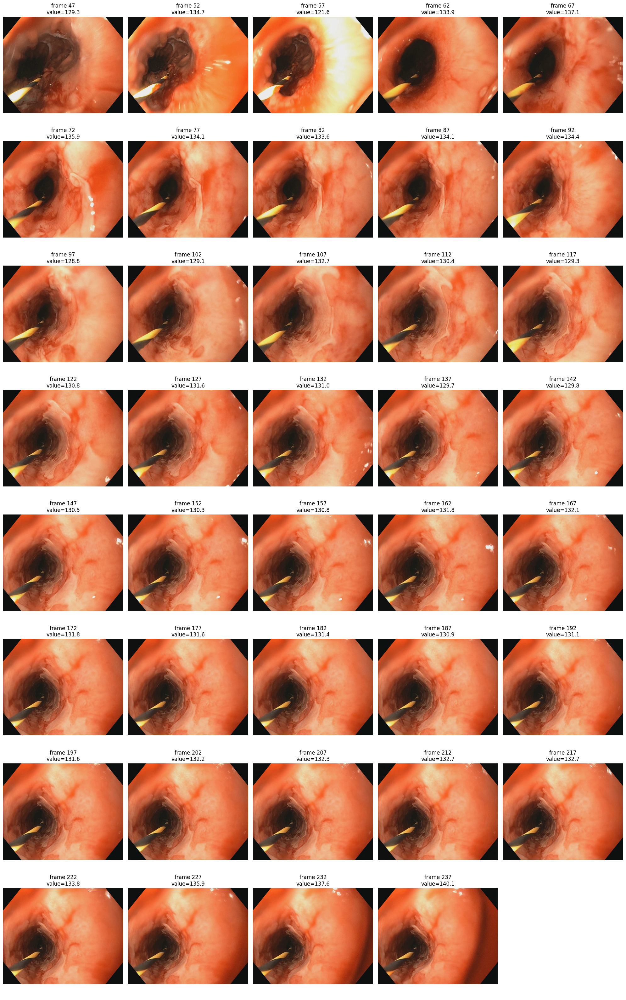

In [52]:
# ---------- SHOW THE ACTUAL FRAMES ----------
def get_frame(video_path, frame_idx):
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    return frame if ret else None


n_cols = 5
n_rows = (len(frames_of_interest) + n_cols - 1) // n_cols  # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()

for ax, idx in zip(axes, frames_of_interest):
    frame = get_frame(video_path, idx)
    if frame is None:
        ax.axis("off")
        continue
    cropped = crop_frame(frame)
    ax.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {idx}\nvalue={values[idx]:.1f}")
    ax.axis("off")

# blank out any leftover empty subplots (e.g. 12 frames only fills 2 of row 3's 5 slots)
for ax in axes[len(frames_of_interest):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

138 -  f-690 not good frame
133.1 - f-693 not good
121.8 - f-650 not good becz it shows the whole guide wirei =inside but this range is geenrally good and it is 
still good based on tissue as it doesnt have glare, white light, or black region alll over and lumen is visible but maybe we can check for vqriation
below 120 generally not good

so this is also a useful observation that it keeps on declining after the it comes out of the lumen

after frame 613 frames are useless in thsi video, so maybe we can also have a window like thing which checks that if like most of the frames after  acertain point are below a threshold then we should like remove 20-30 frames to be on the safe side before that point of change, so that any frames initiating that change are also removed.


120-132 this range seems good

below 110 is certainly out of body

In [243]:
start, end = 0, 100
for idx in range(start, min(end, len(values))):
    print(f"frame {idx:5d}:  value = {values[idx]:.1f}")

frame     0:  value = 139.8
frame     1:  value = 137.9
frame     2:  value = 138.3
frame     3:  value = 141.6
frame     4:  value = 141.6
frame     5:  value = 141.0
frame     6:  value = 140.8
frame     7:  value = 141.5
frame     8:  value = 142.3
frame     9:  value = 141.5
frame    10:  value = 139.3
frame    11:  value = 134.6
frame    12:  value = 135.8
frame    13:  value = 137.3
frame    14:  value = 138.4
frame    15:  value = 139.1
frame    16:  value = 139.4
frame    17:  value = 139.3
frame    18:  value = 139.4
frame    19:  value = 139.4
frame    20:  value = 139.8
frame    21:  value = 139.7
frame    22:  value = 140.9
frame    23:  value = 141.2
frame    24:  value = 137.4
frame    25:  value = 137.1
frame    26:  value = 138.6
frame    27:  value = 140.6
frame    28:  value = 141.6
frame    29:  value = 140.2
frame    30:  value = 138.7
frame    31:  value = 137.8
frame    32:  value = 138.6
frame    33:  value = 139.3
frame    34:  value = 139.6
frame    35:  value 

In [18]:
def show_frame(frame_idx, cropped=True):
    frame = get_frame(video_path, frame_idx)

    if frame is None:
        print(f"Could not read frame {frame_idx}")
        return

    display_frame = crop_frame(frame) if cropped else frame

    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(display_frame, cv2.COLOR_BGR2RGB))
    value = values[frame_idx] if frame_idx < len(values) else None
    title = f"frame {frame_idx}"
    if value is not None:
        title += f"  |  value = {value:.1f}"
    plt.title(title)
    plt.axis("off")
    plt.show()

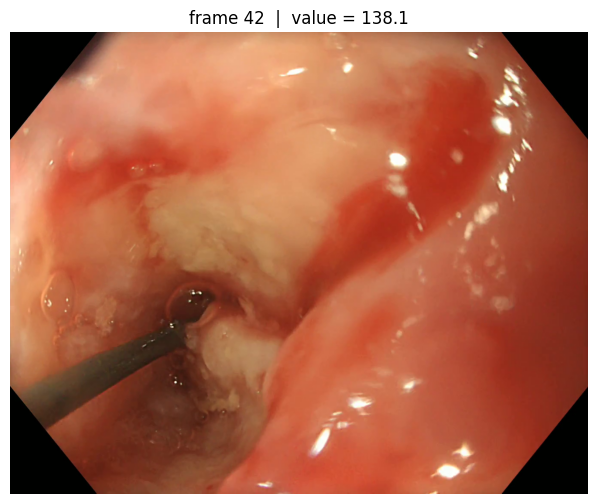

In [193]:
show_frame(42)

## FINAL PIPELINE

In [19]:
def remove_out_of_body_segments(values, survivors, out_of_body_threshold=100):
    """
    Drop any surviving segment whose own median falls below out_of_body_threshold --
    equivalent to "more than 50% of this segment's frames are out-of-body" (median
    below the cutoff means the majority of the segment sits below it). Keeps an
    out-of-body-but-flat segment from contaminating the baseline calculation next.
    """
    values = np.asarray(values)
    clean, dropped = [], []
    for s in survivors:
        seg = values[s["start"]:s["end"]]
        seg_median = float(np.median(seg))
        s["segment_median"] = seg_median
        (dropped if seg_median < out_of_body_threshold else clean).append(s)
    return clean, dropped

In [20]:
def run_pelt(values, pen=500):
    """Run PELT segmentation on the mean_normalized_red series, return raw breakpoints."""
    signal = np.array(values)
    algo = rpt.Pelt(model="l2", min_size=30, jump=1).fit(signal)
    bkps = algo.predict(pen=pen)
    return bkps


In [21]:
def plot_pelt(video_path, values, bkps, pen):
    """Plot the signal with vertical lines at each PELT breakpoint."""
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(values, linewidth=0.8)
    for bkp in bkps[:-1]:
        ax.axvline(x=bkp, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"{video_path.split(chr(92))[-1]}  pen={pen}  breakpoints: {bkps[:-1]}")
    ax.set_xlabel("frame index")
    ax.set_ylabel("mean_normalized_red")
    plt.tight_layout()
    plt.show()


In [22]:
def filter_by_containing_baseline(values, clean_survivors, low_pct=10, high_pct=90, top_trim_pct=90, tolerance=0):
    """
    Baseline = median of pooled per-frame values from just the surviving,
    non-out-of-body segments, with the top 10% trimmed off first -- protects
    the baseline from a stable-but-too-red segment (glare/close-up) skewing it
    upward. No floor cleaning needed here -- out-of-body is already handled
    by remove_out_of_body_segments before this runs.

    A segment is kept if its own value range (10-90 percentile), widened by
    `tolerance` on each side, contains the baseline. Mutates each segment
    dict in `clean_survivors` in place (adds p_low/p_high/contains_baseline).
    """
    values = np.asarray(values)
    pooled = np.concatenate([values[s["start"]:s["end"]] for s in clean_survivors])
    p_top = np.percentile(pooled, top_trim_pct)
    pooled_trimmed = pooled[pooled <= p_top]
    baseline = float(np.median(pooled_trimmed))

    kept = []
    for s in clean_survivors:
        seg = values[s["start"]:s["end"]]
        p_low, p_high = np.percentile(seg, [low_pct, high_pct])
        s["p_low"], s["p_high"] = float(p_low), float(p_high)
        s["contains_baseline"] = bool((p_low - tolerance) <= baseline <= (p_high + tolerance))
        if s["contains_baseline"]:
            kept.append(s)
    return kept, baseline

In [ ]:
def rescue_with_tolerance(values, clean_survivors, baseline, kept, target_pct=15,
                           tolerance_start=0, tolerance_step=0.5, max_tolerance=5,
                           low_pct=10, high_pct=90):
    """
    If kept-frame yield is <= target_pct of total video frames, progressively
    widen the baseline-containment tolerance and rescue the minimum number of
    additional segments needed to clear the threshold -- closest-to-baseline
    segments first, one at a time, rather than pulling in everything that
    newly qualifies at a given tolerance all at once.
    """
    values = np.asarray(values)
    total_frames = len(values)
    kept = list(kept)
    kept_ids = {(s["start"], s["end"]) for s in kept}
    tolerance = tolerance_start
    pending = []

    def pct_kept():
        return 100 * sum(s["end"] - s["start"] for s in kept) / total_frames

    while pct_kept() <= target_pct:
        if not pending:
            tolerance += tolerance_step
            if tolerance > max_tolerance:
                break  # safety cap -- stop trying to rescue further

            newly_qualified = []
            for s in clean_survivors:
                sid = (s["start"], s["end"])
                if sid in kept_ids:
                    continue
                seg = values[s["start"]:s["end"]]
                p_low, p_high = np.percentile(seg, [low_pct, high_pct])
                if (p_low - tolerance) <= baseline <= (p_high + tolerance):
                    newly_qualified.append(s)

            if not newly_qualified:
                continue  # nothing new at this tolerance, keep widening

            newly_qualified.sort(key=lambda s: abs(s["mean"] - baseline))
            pending = newly_qualified

        s = pending.pop(0)
        kept.append(s)
        kept_ids.add((s["start"], s["end"]))

    return kept, tolerance, round(pct_kept(), 1)

In [23]:
def run_pipeline(video_path, pen=500, tolerance=1, max_range=10):
    # 1. per-frame mean_normalized_red (existing functions, called as-is)
    values = compute_mnr_series(video_path)
    if values is None:
        return None
    plot_mean_normalized_red(video_path, values)

    # 2. PELT segmentation -- separate run + plot functions
    bkps = run_pelt(values, pen=pen)
    plot_pelt(video_path, values, bkps, pen)

    # 3. flatness filter (existing function, called as-is)
    survivors, all_segs = filter_by_stability(values, bkps, max_range)
    print("All segments:")
    for s in all_segs:
        print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range_90_10={s['range_90_10']:5.1f}")
    print("\nSurvivors (range_90_10<=10):")
    for s in survivors:
        print(f"  {s['start']:>4}-{s['end']:<4} len={s['length']:<4} mean={s['mean']:6.1f} range_90_10={s['range_90_10']:5.1f}")
    shading_plot(values, all_segs, survivors)

    # 4. drop out-of-body segments (median < 100)
    clean_survivors, dropped_oob = remove_out_of_body_segments(values, survivors)

    if dropped_oob == []:
        print("\nDropped as out-of-body (segment median < 100): None" )
    else:
        print("\nDropped as out-of-body (segment median < 100):")
        for s in dropped_oob:
            print(f"  {s['start']:>4}-{s['end']:<4} median={s['segment_median']:6.1f}")


    # 5. baseline containment filter
    kept, baseline = filter_by_containing_baseline(values, clean_survivors, tolerance=tolerance)
    print("\nbaseline (median of pooled non-OOB survivor frames, top-10% trimmed):", round(baseline, 1))
    for s in clean_survivors:
        print(f"  {s['start']:>4}-{s['end']:<4}  range=[{s['p_low']:.1f}, {s['p_high']:.1f}]  contains_baseline={s['contains_baseline']}")
    print("\nKept (before rescue):", [(s["start"], s["end"]) for s in kept])
    
    shading_plot(values, all_segs, kept)

    # 6. yield percentage
    total_frames = len(values)
    kept_frames = sum(s["end"] - s["start"] for s in kept)
    pct = 100 * kept_frames / total_frames if total_frames else 0.0
    print(f"\nKept frames (before rescue): {kept_frames} / {total_frames}  ({pct:.1f}%)")

    # 7. rescue -- only fires if yield is too low
    if pct <= 15:
        kept, final_tolerance, pct = rescue_with_tolerance(values, clean_survivors, baseline, kept, target_pct=15, tolerance_start=tolerance)
        print(f"\nYield was <=15% -- rescue triggered, widened tolerance to {final_tolerance}")
        print("Kept (after rescue):", [(s['start'], s['end']) for s in kept])
        kept_frames = sum(s["end"] - s["start"] for s in kept)
        print(f"Kept frames (after rescue): {kept_frames} / {total_frames}  ({pct:.1f}%)")
    else:
        print("\nYield above 15% -- rescue not needed")

    shading_plot(values, all_segs, kept)

    return {
        "values": values, "bkps": bkps, "all_segs": all_segs,
        "survivors": survivors, "clean_survivors": clean_survivors,
        "kept": kept, "baseline": baseline, "pct_kept": pct,
        "final_tolerance": final_tolerance,
    }


In [42]:
video_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA2459C_05-05-26_102237.mp4"

frames analyzed: 1091  |  min=120.0  max=172.2  mean=130.9


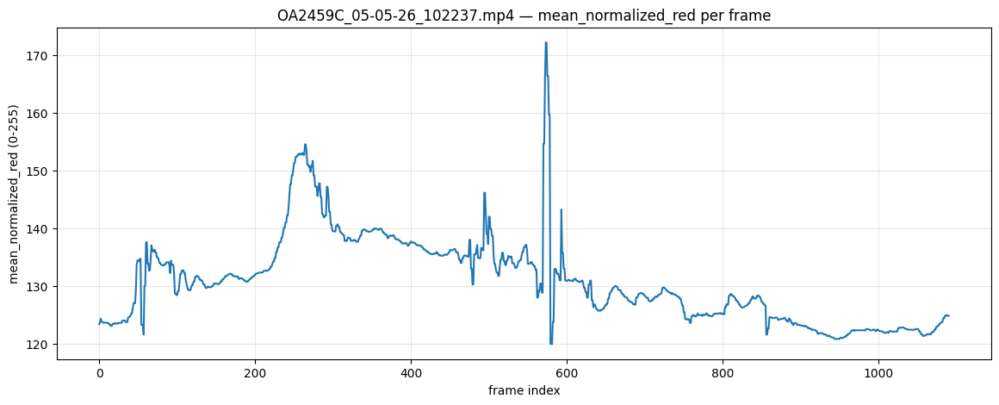

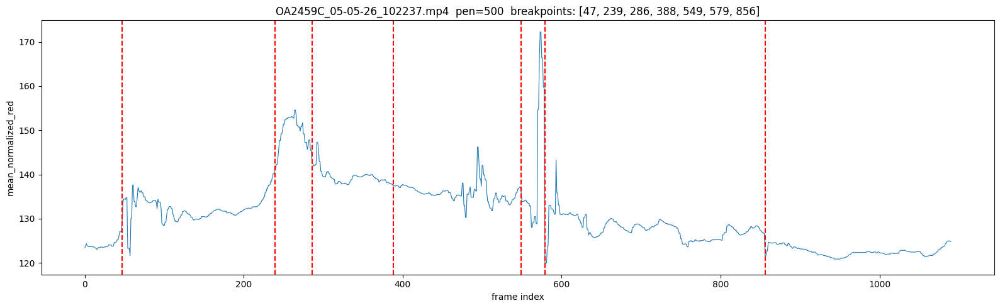

All segments:
     0-47   len=47   mean= 124.1 range_90_10=  1.8
    47-239  len=192  mean= 132.2 range_90_10=  6.0
   239-286  len=47   mean= 149.5 range_90_10=  8.2
   286-388  len=102  mean= 139.5 range_90_10=  3.9
   388-549  len=161  mean= 135.9 range_90_10=  3.8
   549-579  len=30   mean= 141.5 range_90_10= 37.5
   579-856  len=277  mean= 127.8 range_90_10=  6.0
   856-1091 len=235  mean= 122.6 range_90_10=  3.0

Survivors (range_90_10<=10):
     0-47   len=47   mean= 124.1 range_90_10=  1.8
    47-239  len=192  mean= 132.2 range_90_10=  6.0
   239-286  len=47   mean= 149.5 range_90_10=  8.2
   286-388  len=102  mean= 139.5 range_90_10=  3.9
   388-549  len=161  mean= 135.9 range_90_10=  3.8
   579-856  len=277  mean= 127.8 range_90_10=  6.0
   856-1091 len=235  mean= 122.6 range_90_10=  3.0


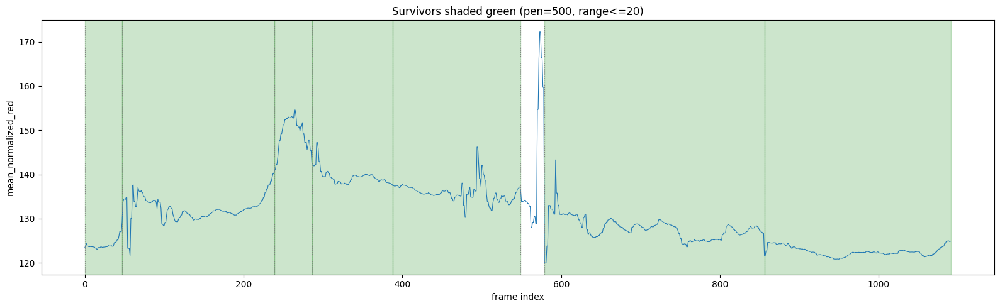


Dropped as out-of-body (segment median < 100): None

baseline (median of pooled non-OOB survivor frames, top-10% trimmed): 128.6
     0-47    range=[123.4, 125.3]  contains_baseline=False
    47-239   range=[129.8, 135.9]  contains_baseline=False
   239-286   range=[144.8, 153.0]  contains_baseline=False
   286-388   range=[137.9, 141.8]  contains_baseline=False
   388-549   range=[133.7, 137.6]  contains_baseline=False
   579-856   range=[125.0, 131.0]  contains_baseline=True
   856-1091  range=[121.4, 124.4]  contains_baseline=False

Kept: [(579, 856)]


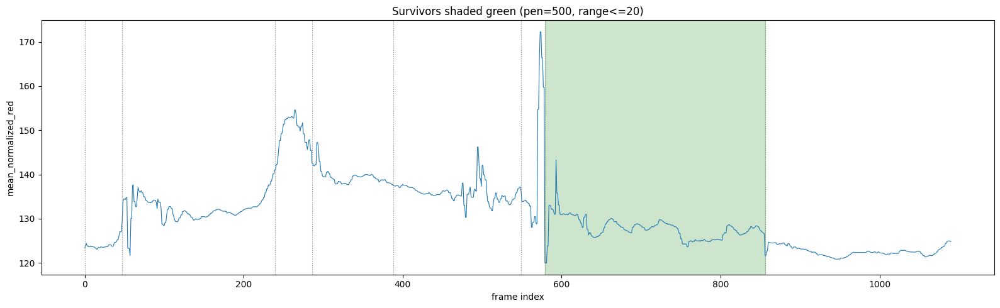


Kept frames: 277 / 1091  (25.4%)


In [43]:
final_result = run_pipeline(video_path, pen=500, tolerance=1, max_range=10)

In [88]:
# final_percentages = []

In [41]:
final_percentages.append({
    "video": os.path.splitext(os.path.basename(video_path))[0],
    "final_frame_percentage": final_result['pct_kept']
})

for fp in final_percentages:
    print(f"Video: {fp['video']}        Final_Percentage: {fp['final_frame_percentage']}")

NameError: name 'final_percentages' is not defined

In [37]:
video_folder = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos"
video_extensions = ("*.mp4", "*.avi", "*.mov", "*.mkv")

video_paths = []
for ext in video_extensions:
    video_paths.extend(glob.glob(os.path.join(video_folder, "**", ext), recursive=True))


In [38]:
video_paths

['C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O983C19_12-06-25_101337.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O983C20_12-06-25_101352.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O99242D_11-07-25_093158.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O9C3E27_24-10-25_090146.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O9E3CEC_07-01-26_092102.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA08324_23-03-26_102243.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA2459C_05-05-26_102237.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA245A0_05-05-26_102303.mp4']

In [ ]:
'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O983C19_12-06-25_101337.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O983C20_12-06-25_101352.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O99242D_11-07-25_093158.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O9C3E27_24-10-25_090146.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\O9E3CEC_07-01-26_092102.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA08324_23-03-26_102243.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA2459C_05-05-26_102237.mp4',
 'C:\\Users\\ahmed\\Documents\\Jobs\\Klinikum Oldenburg\\Selected_videos\\OA245A0_05-05-26_102303.mp4'

3rd vidoe shows that 7 max range for 10-90 percentile stable function is also good. threshold at 1 got some good segments
2nd video doesnt support this, it shows values at 8.7 mostly which are taken have no impact becz other 2 were very high, not close, also has peaks within segment
1st video doesnt supoort max range of 10, it also has peaks within segments, tolerance has no impact, others very far
4th video also worked as above, only had 2 segments as it is short video.
6trh video works good but out of 2, 1 segment had mnost of the images with white baloon in the midddle which are not needed, aalmost all images are usless, maybe next filters will filter those out, for now ntg else can be done here to solve that
7th video -> tolerane if greater than 1 would bring in one more segment that we dont want so lets keeep it 1.

most of the percenatges are >= 20%, you can also create 2 latyers of checking like once percentage with total frames and 1 with non OOB frames if both less than 15% then take  action and increase threhsold by 1, check again 